# 03 — Identificazione del modello e risultati

Materiale per i capitoli di **identificazione, confronto fra modelli, analisi dei residui
e simulatore**: teoria essenziale, risultato coi suoi numeri, e cosa significa.

In [1]:
# --- Grafici interattivi (zoom, pan, salvataggio dalla toolbar) ---------------
# Il backend `widget` di ipympl rende zoomabili le figure matplotlib direttamente
# nel notebook, senza cambiare una riga del codice di disegno. Se ipympl non e'
# installato si ricade sul backend statico `inline`, cosi' il notebook resta
# eseguibile ovunque; impostare MPL_STATIC=1 forza il comportamento statico.
import os

from IPython import get_ipython

_ip = get_ipython()
if os.environ.get("MPL_STATIC") or _ip is None:
    _BACKEND = "inline"
else:
    try:
        import ipympl  # noqa: F401
        _BACKEND = "widget"
    except ImportError:
        _BACKEND = "inline"
if _ip is not None:
    _ip.run_line_magic("matplotlib", _BACKEND)

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

DATA_RAW = ROOT / "data" / "raw" / "dati_tesi"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from src.fitting import fit_all_movements, load_movements_from_processed
from src.validation import (
    ValidationConfig,
    check_amax_consistency_across_speeds,
    compute_residuals_summary,
    motion_window,
    plot_amax_across_speeds,
    plot_residuals_histogram,
    plot_residuals_qq,
    plot_residuals_vs_time,
    summarize_by_joint,
    validate_all_movements,
)

QUANTO = 1.4e-3      # quantizzazione dell'encoder [rad] = 0.08 deg

print(f"backend matplotlib: {_BACKEND}"      + ("  (grafici interattivi)" if _BACKEND == "widget" else "  (statico)"))

/home/lorenzo/introb/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


backend matplotlib: inline  (statico)


## 1. Dataset e metodo

```
acquisizione 25 Hz  ->  Modulo 1: filtro, derivate, stime preliminari
                    ->  Modulo 2: profilo teorico analitico
                    ->  Modulo 3: fit ai minimi quadrati sulla posizione grezza
                    ->  Modulo 4: confronto fra modelli e validazione dei residui
```

In [2]:
# fit_results.csv e' l'uscita del Modulo 3. Se manca lo si rigenera qui, cosi'
# la pipeline e' riproducibile dai soli notebook.
from src.fitting import fit_all_movements, load_movements_from_processed

if not (DATA_PROCESSED / "fit_results.csv").exists():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _mov = load_movements_from_processed(
            DATA_PROCESSED / "preprocessing_params.csv", raw_root=DATA_RAW
        )
        fit_all_movements(_mov, output_path=DATA_PROCESSED / "fit_results.csv")
    print("fit_results.csv rigenerato")
else:
    print("fit_results.csv gia' presente")

fit_results.csv gia' presente


In [3]:
params = pd.read_csv(DATA_PROCESSED / "preprocessing_params.csv")
fit = pd.read_csv(DATA_PROCESSED / "fit_results.csv")

# Le due tabelle si appaiano su (sessione, giunto, segmento).
dati = params.merge(
    fit.drop(columns=["commanded_velocity", "delta_q", "source"]),
    on=["session", "joint_name", "segment_index"],
)

pd.DataFrame([{
    "sessioni": params.session.nunique(),
    "movimenti": len(dati),
    "giunti": params.joint_name.nunique(),
    "velocita' comandate": ", ".join(str(int(v)) for v in sorted(params.commanded_velocity.unique())),
    "frequenza [Hz]": round(params.fs.median(), 2),
    "escursione media [rad]": round(params.delta_q.abs().mean(), 3),
    "quantizzazione encoder [rad]": QUANTO,
}]).T.rename(columns={0: "valore"})
None

## 2. Dal profilo teorico al fit

Un caso di studio su tre movimenti reali, per mostrare come si passa dalle stime del
Modulo 1 ai parametri identificati dal fit.

### Il profilo a tempo minimo, in forma chiusa

Il modello da identificare è la traiettoria che porta un giunto da `q0` a `qf` nel **minor
tempo possibile** con velocità limitata a `vmax` e accelerazione a `amax`. Ha tre fasi —
accelerazione `+amax`, crociera a `vmax`, decelerazione `−amax` — da cui il nome
*trapezoidale*, che descrive la forma del profilo di velocità.

Le due rampe durano `t_acc = vmax/amax` ciascuna e coprono insieme
$\Delta q_{crit} = v_{max}^2 / a_{max}$, da cui la **soglia di commutazione**:

* `|Δq| ≥ vmax²/amax` → **trapezoidale**, plateau di durata `(|Δq| − Δq_crit)/vmax`;
* `|Δq| < vmax²/amax` → **triangolare**: la crociera non si raggiunge e si tocca
  `v_peak = √(amax·|Δq|) < vmax`.

I due casi non richiedono formule separate: imponendo al trapezoidale la velocità
equivalente `√(amax·|Δq|)` il plateau si annulla e si ottiene il triangolare.

**Il parametro nascosto è `t0`**: fra il comando sulla seriale e il primo campione in moto
passa un ritardo non predicibile, quindi entra nel fit come parametro libero.

In [4]:
from src.preprocessing import (
    PreprocessingConfig, analyze_joint_movement, load_position_data, segment_movements,
)
from src.trajectory_models import profile_times, trapezoidal_position
from src.fitting import build_initial_guess, estimate_t0, fit_single_movement

# Tre movimenti della sessione 1_50, scelti per essere leggibili nei grafici.
_df = load_position_data(DATA_RAW / "1_50" / "mycobot280_angle_data.npy")
_t = _df.iloc[:, 0].to_numpy()
_nomi = list(_df.columns[1:])
_segmenti = segment_movements(_t, _df[_nomi].to_numpy(), joint_names=_nomi)
scelti = [_segmenti[0], _segmenti[3], _segmenti[8]]   # j1 avanti, j2 indietro, j5 avanti

cfg_pre = PreprocessingConfig()
risultati = []
for s in scelti:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        risultati.append(analyze_joint_movement(
            time=s.time, position=s.position, cutoff_hz=cfg_pre.cutoff_hz,
            order=cfg_pre.filter_order, config=cfg_pre,
            joint_name=s.joint_name, segment_index=s.index,
        ))

pd.DataFrame([{
    "giunto": r.joint_name, "delta_q [rad]": round(r.delta_q, 3),
    "vmax M1 [rad/s]": round(r.vmax_est, 4),
    "amax M1 [rad/s^2]": round(r.amax_est, 3),
    "profilo": r.profile_type,
    "amax affidabile": r.amax_reliable,
} for r in risultati])
None

### L'istante di partenza domina il confronto

Il Modulo 1 non stima `t0`, e ricavarlo da una soglia lo quantizza a un campione (40 ms).
Sul plateau un disallineamento `δ` produce un offset `vmax·δ`: con `vmax ≈ 1.3 rad/s`
bastano 40 ms per **0.05 rad** di errore, più di qualunque differenza di forma fra i
profili candidati.

In [5]:
def confronta(res, t0):
    """Profilo teorico con partenza in t0, contro la posizione filtrata."""
    q0 = float(res.position_filtered[0])
    qf = q0 + res.delta_q
    tempi = profile_times(q0, qf, res.vmax_est, res.amax_est)
    posizione = trapezoidal_position(res.time - t0, q0, qf, res.vmax_est, res.amax_est)
    return tempi, posizione, res.position_filtered - posizione


confronti = []
for res in risultati:
    t0_grezzo = estimate_t0(res.time, res.position_filtered)
    tm, _, res_g = confronta(res, t0_grezzo)

    # Raffinamento in forma chiusa (nessuna ottimizzazione): un ritardo delta produce
    # sul plateau un offset costante pari a v*delta, quindi basta annullare il
    # residuo medio in quella finestra.
    plateau = ((res.time >= t0_grezzo + tm.t_acc) &
               (res.time <= t0_grezzo + tm.t_acc + tm.t_flat))
    t0_raff = t0_grezzo - float(np.mean(res_g[plateau])) / (tm.sign * res.vmax_est)
    _, pos_r, res_r = confronta(res, t0_raff)

    confronti.append({"res": res, "teorico": pos_r, "t0_raff": t0_raff,
                      "residuo_grezzo": res_g, "residuo": res_r,
                      "rmse_grezzo": float(np.sqrt(np.mean(res_g**2))),
                      "rmse": float(np.sqrt(np.mean(res_r**2)))})

pd.DataFrame([{
    "giunto": c["res"].joint_name,
    "correzione t0 [campioni]": round(
        (c["t0_raff"] - estimate_t0(c["res"].time, c["res"].position_filtered))
        * c["res"].fs, 2),
    "RMSE prima [rad]": round(c["rmse_grezzo"], 5),
    "RMSE dopo [rad]": round(c["rmse"], 5),
    "miglioramento": f"{c['rmse_grezzo'] / c['rmse']:.1f}x",
} for c in confronti])
None

Una correzione inferiore a un campione e mezzo abbatte l'RMSE di un fattore 10 o più: è la
ragione per cui `t0` è parametro libero del fit e non una stima congelata a parte.

### Il fit sulla posizione grezza

L'ottimizzazione lavora su `vmax`, `amax` e `t0` insieme, sulla posizione **grezza**: il
filtro serviva al Modulo 1 per poter derivare, il fit non deriva nulla e confronta il
modello direttamente coi campioni acquisiti.

In [6]:
def residuo_grezzo(res, vmax, amax, t0):
    q0 = float(res.position_raw[0])
    modello = np.asarray(
        trapezoidal_position(res.time - t0, q0, q0 + res.delta_q, vmax, amax))
    return modello - res.position_raw


casi = []
for c in confronti:
    res = c["res"]
    q0 = float(res.position_raw[0])
    esito = fit_single_movement(
        t_data=res.time, q_data=res.position_raw, q0=q0, qf=q0 + res.delta_q,
        initial_guess=build_initial_guess(
            res.vmax_est, res.amax_est, estimate_t0(res.time, res.position_raw)),
        profile_type=res.profile_type, joint_name=res.joint_name,
        segment_index=res.segment_index,
    )
    casi.append({"res": res, "esito": esito,
                 "r_prima": residuo_grezzo(res, res.vmax_est, res.amax_est, c["t0_raff"]),
                 "r_dopo": esito.residuals})

pd.DataFrame([{
    "giunto": k["res"].joint_name,
    "vmax M1": round(k["res"].vmax_est, 4),
    "vmax fit": round(k["esito"].vmax_fit, 4),
    "amax M1": round(k["res"].amax_est, 3),
    "amax fit": round(k["esito"].amax_fit, 3),
    "amax +%": round(100 * (k["esito"].amax_fit - k["res"].amax_est) / k["res"].amax_est, 1),
    "RMSE dopo": round(k["esito"].rmse, 5),
    "campioni rampa": round(k["esito"].ramp_samples, 1),
    "amax identif.": k["esito"].amax_identifiable,
} for k in casi])

,giunto,vmax M1,vmax fit,amax M1,amax fit,amax +%,RMSE dopo,campioni rampa,amax identif.
0,j1,1.3186,1.3180,5.419,6.715,23.9,0.00122,4.9,False
1,j2,1.3261,1.3283,6.015,7.608,26.5,0.00234,4.4,False
2,j5,1.3182,1.3154,6.051,15.257,152.1,0.00150,2.2,False


`vmax` non si sposta: il fit la conferma alla quarta cifra. `amax` sale nella direzione che
il Modulo 1 aveva previsto marcandoli `amax_reliable = False`, ma su questi tre movimenti
la rampa copre 2–5 campioni e il valore non è affidabile: che la correzione sia reale si
dimostra sull'intero dataset.

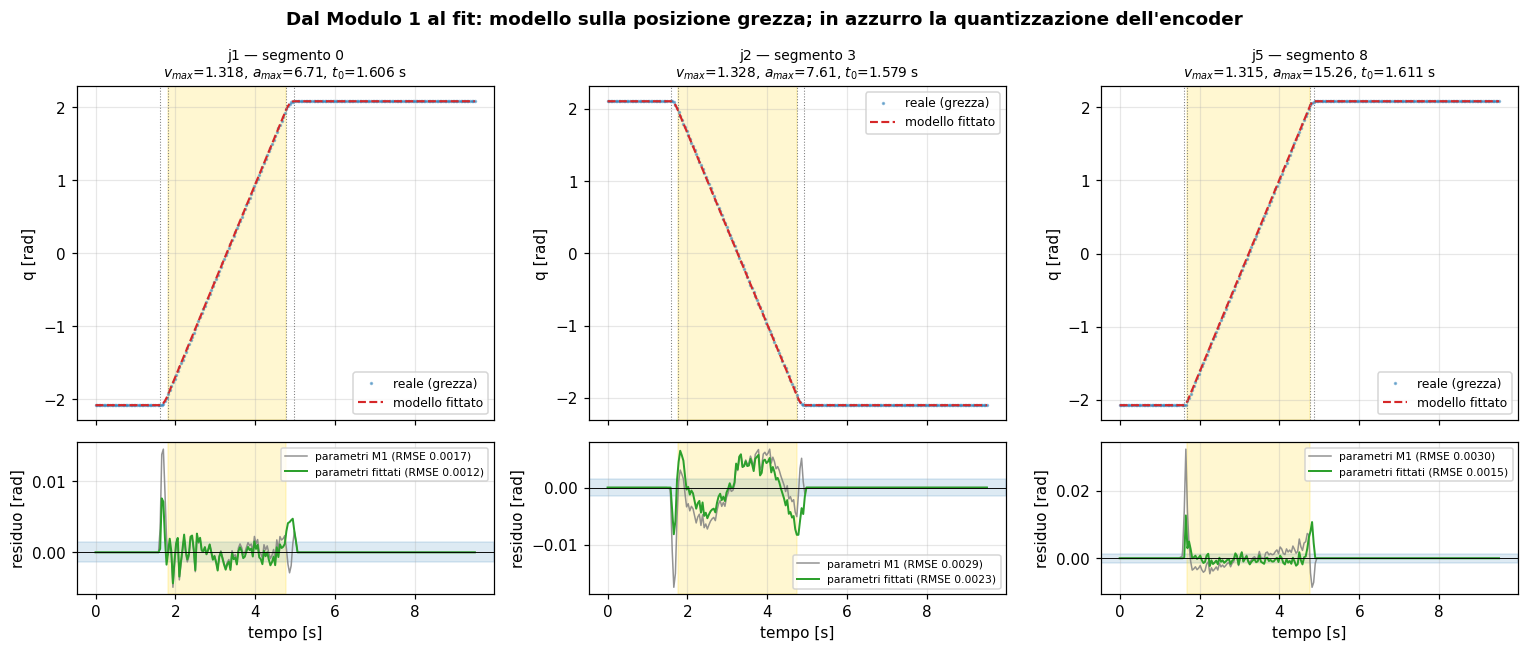

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex="col",
                         gridspec_kw={"height_ratios": [2.2, 1]})

for j, k in enumerate(casi):
    res, esito = k["res"], k["esito"]
    tt = res.time
    q0 = float(res.position_raw[0])
    teorico = np.asarray(trapezoidal_position(
        tt - esito.t0_fit, q0, q0 + res.delta_q, esito.vmax_fit, esito.amax_fit))

    t_acc = esito.vmax_fit / esito.amax_fit
    t_fine = esito.t0_fit + abs(res.delta_q) / esito.vmax_fit + t_acc
    bordi = (esito.t0_fit, esito.t0_fit + t_acc, t_fine - t_acc, t_fine)

    ax = axes[0, j]
    ax.plot(tt, res.position_raw, ".", ms=2.5, alpha=0.45, color="C0",
            label="reale (grezza)")
    ax.plot(tt, teorico, lw=1.4, color="C3", ls="--", label="modello fittato")
    ax.axvspan(bordi[1], bordi[2], color="gold", alpha=0.18)
    for b in bordi:
        ax.axvline(b, color="grey", lw=0.7, ls=":")
    ax.set_ylabel("q [rad]")
    ax.set_title(f"{res.joint_name} — segmento {res.segment_index}\n"
                 f"$v_{{max}}$={esito.vmax_fit:.3f}, $a_{{max}}$={esito.amax_fit:.2f}, "
                 f"$t_0$={esito.t0_fit:.3f} s", fontsize=9)
    ax.legend(fontsize=8, loc="best")

    ax = axes[1, j]
    ax.plot(tt, k["r_prima"], lw=1.0, color="grey", alpha=0.85,
            label=f"parametri M1 (RMSE {np.sqrt(np.mean(k['r_prima']**2)):.4f})")
    ax.plot(tt, k["r_dopo"], lw=1.3, color="C2",
            label=f"parametri fittati (RMSE {esito.rmse:.4f})")
    ax.axhline(0, color="k", lw=0.6)
    ax.axhspan(-1.4e-3, 1.4e-3, color="C0", alpha=0.15)
    ax.axvspan(bordi[1], bordi[2], color="gold", alpha=0.18)
    ax.set(ylabel="residuo [rad]", xlabel="tempo [s]")
    ax.legend(fontsize=7, loc="best")

fig.suptitle("Dal Modulo 1 al fit: modello sulla posizione grezza; in azzurro la "
             "quantizzazione dell'encoder", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "03_dal_teorico_al_fit.png", dpi=150, bbox_inches="tight")
plt.show()

La fascia azzurra è la quantizzazione dell'encoder, ±1.4·10⁻³ rad. Dopo il fit il residuo
ci sta quasi interamente dentro: **il modello non lascia struttura inspiegata oltre il
rumore di misura**. Restano piccoli sussulti ai raccordi, che le sezioni sui residui
quantificano.

## 3. Profili identificati

I 132 movimenti sono fittati **uno per uno**: la dispersione fra giunti, direzioni e
ripetizioni è il dato su cui si regge la validazione di consistenza.

In [8]:
print(f"convergenza     : {fit.success.sum()}/{len(fit)} ({100*fit.success.mean():.1f}%)")
print(f"profili         : {fit.profile_type.value_counts().to_dict()}")
print(f"branch_changed  : {fit.branch_changed.sum()}")
print(f"amax identific. : {fit.amax_identifiable.sum()}/{len(fit)}")

parametri = dati.groupby("commanded_velocity").agg(
    n=("vmax_fit", "size"),
    vmax=("vmax_fit", "mean"),
    vmax_std=("vmax_fit", "std"),
    amax=("amax_fit", "mean"),
    amax_std=("amax_fit", "std"),
    t0=("t0_fit", "mean"),
    rampa_campioni=("ramp_samples", "median"),
).round(4)
parametri.to_csv(TABLES / "03_parametri_identificati.csv")
parametri

convergenza     : 132/132 (100.0%)
profili         : {'trapezoidal': 132}
branch_changed  : 0
amax identific. : 86/132


,n,vmax,vmax_std,amax,amax_std,t0,rampa_campioni
commanded_velocity,,,,,,,
25,12,0.6588,0.0035,20.2419,33.7047,1.5830,3.0460
50,36,1.3170,0.0079,8.7121,2.2107,1.5871,4.1502
75,36,1.9763,0.0119,8.1844,0.7075,1.5805,6.1098
100,48,2.6368,0.0163,8.0641,0.3101,1.5793,8.2641


`vmax` ha dispersione sotto l'1% a tutte e quattro le velocità. `amax` no, e la colonna
`rampa_campioni` spiega perché: la rampa dura `vmax/amax`, e poiché `vmax` cresce col
comando mentre `amax` resta costante, al comando più basso è peggio risolta.

| comando | campioni nella rampa | `amax` [rad/s²] | dispersione |
|---|---|---|---|
| 25 | ~3 | 20.24 | ±33.7 (166%) |
| 50 | ~4 | 8.71 | ±2.2 (25%) |
| 75 | ~6 | 8.18 | ±0.71 (8.7%) |
| 100 | ~8 | 8.06 | ±0.31 (3.8%) |

La dispersione crolla di **un fattore 40**. Non è il robot a essere più regolare alle alte
velocità: è il residuo a diventare **insensibile** ad `amax` quando la rampa copre pochi
campioni, e l'RMSE resta identico alle quattro velocità. Da qui il flag
`amax_identifiable` con soglia a 5 campioni: nel seguito si usano gli **86 movimenti** che
la superano.

**Controllo incrociato su `vmax`:** i due metodi indipendenti concordano con scarto
relativo mediano dello **0.09%**, sotto lo 0.31% su tutti i 132 movimenti.

## 4. Confronto fra modelli e selezione

Il trapezoidale riproduce la posizione entro il rumore di misura, ma **essere sufficiente
non vuol dire essere giusto**. Tre candidati sugli stessi 132 movimenti:

| candidato | parametri liberi | k | perché è in gara |
|---|---|---|---|
| **trapezoidale** | `vmax, amax, t0` | 3 | il riferimento |
| **trapezoidale asimmetrico** | `vmax, a_acc, a_dec, t0` | 4 | i residui mostrano un picco in accelerazione quasi doppio di quello in decelerazione |
| **quintico** | `t_move, t0` | 2 | controllo negativo: liscio ma **senza plateau** |

Il quintico verifica che il criterio discrimini sulla forma e non premi la parsimonia.

> **Due condizioni di validità.** `AIC = n·ln(RSS/n) + 2k` è confrontabile solo a parità di
> campioni, quindi tutti i candidati usano la **stessa** finestra. E poiché i residui sono
> autocorrelati per costruzione, si guarda il **numero di vittorie**, non la magnitudine di
> ΔAIC.

In [9]:
from src.validation import aggregate_model_comparison, compare_models

# Ogni movimento viene fittato coi tre candidati e valutato sulla finestra
# comune. Con i Jacobiani numerici dei tre profili estesi e' la cella piu' lenta
# del notebook: circa un minuto.
pezzi = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    movimenti_cfr = load_movements_from_processed(
        DATA_PROCESSED / "preprocessing_params.csv", raw_root=DATA_RAW
    )
    for chiave, mov in movimenti_cfr.items():
        tab = compare_models(
            mov["t_data"], mov["q_data"], mov["q0"], mov["qf"],
            vmax_est=mov["vmax_est"], amax_est=mov["amax_est"],
        )
        if tab.empty:
            continue
        tab["movimento"] = chiave
        tab["joint_name"] = mov["joint_name"]
        tab["commanded_velocity"] = mov["commanded_velocity"]
        pezzi.append(tab)

confronto = pd.concat(pezzi, ignore_index=True)
confronto.to_csv(DATA_PROCESSED / "model_comparison.csv", index=False)

sintesi = aggregate_model_comparison(confronto)
sintesi.to_csv(TABLES / "04_confronto_modelli.csv", index=False)
sintesi[["profile_type", "n_params", "n_convergenti", "rmse_quanti_mediano",
         "delta_aic_mediano", "n_vittorie", "n_vittorie_decisive"]].round(2)

,profile_type,n_params,n_convergenti,rmse_quanti_mediano,delta_aic_mediano,n_vittorie,n_vittorie_decisive
0,asymmetric_trapezoidal,4,132,1.72,-29.90,122,113
1,trapezoidal,3,132,2.36,0.00,10,0
2,quintic,2,132,61.49,385.56,0,0


### Il risultato

**Vince il trapezoidale asimmetrico**, su 122 movimenti su 132 e in 113 casi con ΔAIC oltre
10 punti. Il residuo mediano scende da 2.36 a 1.72 quanti di encoder — **−27%**, ben oltre
l'1.7% che sarebbe bastato a ripagare il parametro in più.

Non è una sorpresa a posteriori ma un esito **predetto dai dati**, dal picco di residuo in
accelerazione quasi doppio di quello in decelerazione. Il simmetrico resta migliore su 10
movimenti, quelli con asimmetria piccola. **Il quintico perde di 386 punti** con un residuo
quaranta volte il riferimento, pur avendo meno parametri di tutti.

In [10]:
# Sensibilita': le stesse metriche sull'intero segmento invece che sulla
# finestra di moto. Se il ranking cambiasse, dipenderebbe dalla finestra.
piena = confronto[confronto.success].copy()
durata = piena.pivot_table(index="movimento", columns="profile_type", values="t_total")
eccesso = durata.sub(durata["trapezoidal"], axis=0) / 0.04   # in campioni

print("Durata predetta rispetto al trapezoidale [campioni a 25 Hz]:")
for c in ["asymmetric_trapezoidal", "quintic"]:
    print(f"  {c:24s} mediana {eccesso[c].median():+6.2f}   "
          f"massimo {eccesso[c].max():+6.2f}")

print("\nL'asimmetrico predice praticamente la stessa durata del riferimento,")
print("quindi la sua vittoria non e' un effetto della finestra scelta.")

Durata predetta rispetto al trapezoidale [campioni a 25 Hz]:
  asymmetric_trapezoidal   mediana  -0.01   massimo  +1.17
  quintic                  mediana +25.98   massimo +78.71

L'asimmetrico predice praticamente la stessa durata del riferimento,
quindi la sua vittoria non e' un effetto della finestra scelta.


L'asimmetrico predice una durata **identica** al riferimento (scarto mediano di un
centesimo di campione), quindi la finestra comune non lo favorisce. Sull'intero segmento il
ranking non cambia ma le magnitudini si moltiplicano per quattro (ΔAIC da −30 a −107),
perché `n` passa da 59 a ~230 con campioni che non portano informazione: la finestra di
moto è la scala giusta.

## 5. Qualità del fit e analisi dei residui

Il residuo è ciò che il modello **non** spiega, e il riferimento naturale è la
quantizzazione dell'encoder, 0.08° = 1.4·10⁻³ rad: sotto quella soglia non c'è nulla da
spiegare, è rumore di misura.

RMSE mediano : 0.00172 rad  (1.23 quanti di encoder)
RMSE min/max : 0.00057 / 0.00647 rad
errore max   : mediano 0.01001 rad
valutazioni  : mediana 8 del modello


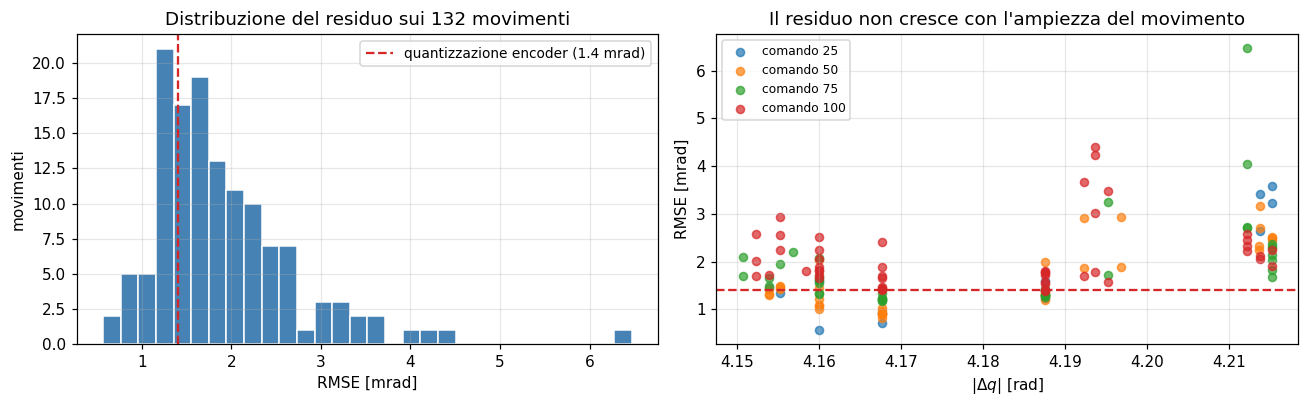

In [11]:
print(f"RMSE mediano : {fit.rmse.median():.5f} rad  "
      f"({fit.rmse.median()/QUANTO:.2f} quanti di encoder)")
print(f"RMSE min/max : {fit.rmse.min():.5f} / {fit.rmse.max():.5f} rad")
print(f"errore max   : mediano {fit.max_abs_residual.median():.5f} rad")
print(f"valutazioni  : mediana {fit.n_function_evals.median():.0f} del modello")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

ax = axes[0]
ax.hist(fit.rmse * 1e3, bins=30, color="steelblue", edgecolor="white")
ax.axvline(QUANTO * 1e3, color="C3", ls="--", lw=1.5,
           label=f"quantizzazione encoder ({QUANTO*1e3:.1f} mrad)")
ax.set(xlabel="RMSE [mrad]", ylabel="movimenti",
       title="Distribuzione del residuo sui 132 movimenti")
ax.legend(fontsize=9)

ax = axes[1]
for vel, gruppo in dati.groupby("commanded_velocity"):
    ax.scatter(gruppo.delta_q.abs(), gruppo.rmse * 1e3, s=28, alpha=0.7,
               label=f"comando {int(vel)}")
ax.axhline(QUANTO * 1e3, color="C3", ls="--", lw=1.5)
ax.set(xlabel=r"$|\Delta q|$ [rad]", ylabel="RMSE [mrad]",
       title="Il residuo non cresce con l'ampiezza del movimento")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "03_qualita_fit.png", dpi=150, bbox_inches="tight")
plt.show()

### Dove si concentra il residuo

Un residuo uniforme sarebbe rumore; un residuo **localizzato** è struttura che il modello
non cattura. Il tempo è normalizzato sulla durata del movimento (0 partenza, 1 arrivo) per
poter mediare fra movimenti di durata diversa.

In [12]:
# Il CSV contiene le metriche aggregate ma non i residui campione per campione:
# si rifà il fit conservandoli.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    movimenti = load_movements_from_processed(
        DATA_PROCESSED / "preprocessing_params.csv", raw_root=DATA_RAW
    )
    risultati, _ = fit_all_movements(movimenti)

GRIGLIA = np.linspace(0.0, 1.0, 200)
accumulo, frazioni_rampa = [], []

for chiave, r in zip(movimenti, risultati):
    if not r.success or r.residuals is None or r.vmax_fit is None:
        continue
    t_acc = r.vmax_fit / r.amax_fit
    t_tot = abs(r.delta_q) / r.vmax_fit + t_acc
    fase = (movimenti[chiave]["t_data"] - r.t0_fit) / t_tot
    dentro = (fase >= 0) & (fase <= 1)
    if dentro.sum() < 10:
        continue
    accumulo.append(np.interp(GRIGLIA, fase[dentro], np.abs(r.residuals[dentro])))
    frazioni_rampa.append(t_acc / t_tot)

profilo_residuo = np.vstack(accumulo)
frazione_rampa = float(np.median(frazioni_rampa))
print(f"movimenti mediati: {profilo_residuo.shape[0]}")
print(f"la rampa occupa in media il {100*frazione_rampa:.1f}% del movimento")

movimenti mediati: 132
la rampa occupa in media il 10.4% del movimento


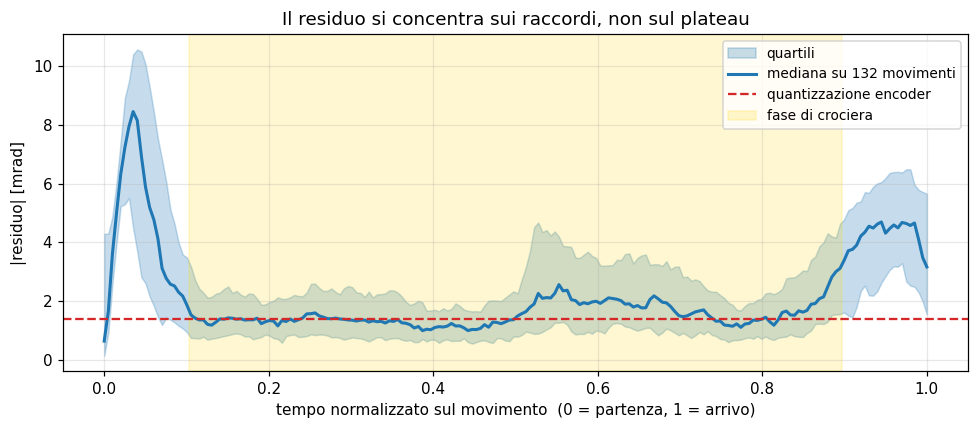

|residuo| mediano in crociera : 1.398 mrad
|residuo| mediano sulle rampe : 4.405 mrad


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))

mediana = np.median(profilo_residuo, axis=0) * 1e3
q1, q3 = np.percentile(profilo_residuo, [25, 75], axis=0) * 1e3

ax.fill_between(GRIGLIA, q1, q3, alpha=0.25, color="C0", label="quartili")
ax.plot(GRIGLIA, mediana, lw=2, color="C0", label=f"mediana su {len(profilo_residuo)} movimenti")
ax.axhline(QUANTO * 1e3, color="C3", ls="--", lw=1.5, label="quantizzazione encoder")
ax.axvspan(frazione_rampa, 1 - frazione_rampa, color="gold", alpha=0.18,
           label="fase di crociera")

ax.set(xlabel="tempo normalizzato sul movimento  (0 = partenza, 1 = arrivo)",
       ylabel="|residuo| [mrad]",
       title="Il residuo si concentra sui raccordi, non sul plateau")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "03_residuo_per_fase.png", dpi=150, bbox_inches="tight")
plt.show()

crociera = (GRIGLIA > frazione_rampa) & (GRIGLIA < 1 - frazione_rampa)
print(f"|residuo| mediano in crociera : {np.median(mediana[crociera]):.3f} mrad")
print(f"|residuo| mediano sulle rampe : {np.median(mediana[~crociera]):.3f} mrad")

Sul tratto a velocità costante il residuo vale 1.40 mrad, cioè **esattamente la
quantizzazione dell'encoder**: lì il modello è indistinguibile dal vero. I picchi cadono
sui raccordi, dove il trapezoidale ideale ha discontinuità di accelerazione che il robot
non può eseguire.

Il picco in **accelerazione (~8.4 mrad) è quasi il doppio di quello in decelerazione
(~4.6 mrad)**: il modello impone rampe simmetriche, il robot no. È l'argomento a favore del
profilo asimmetrico. C'è poi un rigonfiamento largo e basso (~2.5 mrad) attorno al 55–70%
del movimento, dentro la crociera: possibile effetto di coppia dipendente dalla
configurazione, che un modello cinematico non contempla.

## 6. Relazione fra comando e parametri fisici

Il parametro `MOVEMENT_VELOCITY` dello script di acquisizione è un intero 1–100 senza
unità di misura documentata. Il fit permette di dargliene una.

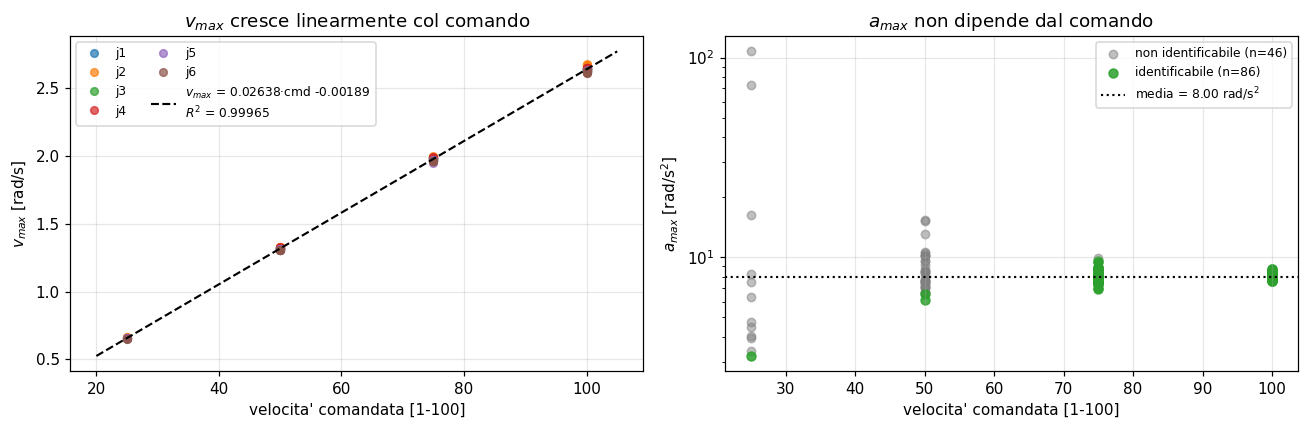

vmax = 0.02638 * comando -0.00189 rad/s   (R^2 = 0.99965)
amax = 7.996 +- 0.753 rad/s^2  (n = 86)


In [14]:
coef = np.polyfit(dati.commanded_velocity, dati.vmax_fit, 1)
residuo_lin = dati.vmax_fit - np.polyval(coef, dati.commanded_velocity)
r2 = 1 - np.var(residuo_lin) / np.var(dati.vmax_fit)

identificabili = dati[dati.amax_identifiable]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for nome, gruppo in dati.groupby("joint_name"):
    ax.plot(gruppo.commanded_velocity, gruppo.vmax_fit, "o", ms=5, alpha=0.7, label=nome)
vel = np.linspace(20, 105, 50)
ax.plot(vel, np.polyval(coef, vel), "k--", lw=1.4,
        label=f"$v_{{max}}$ = {coef[0]:.5f}·cmd {coef[1]:+.5f}\n$R^2$ = {r2:.5f}")
ax.set(xlabel="velocita' comandata [1-100]", ylabel=r"$v_{max}$ [rad/s]",
       title="$v_{max}$ cresce linearmente col comando")
ax.legend(fontsize=8, ncol=2)

ax = axes[1]
non_id = dati[~dati.amax_identifiable]
ax.scatter(non_id.commanded_velocity, non_id.amax_fit, s=30, alpha=0.5,
           color="grey", label=f"non identificabile (n={len(non_id)})")
ax.scatter(identificabili.commanded_velocity, identificabili.amax_fit, s=34,
           alpha=0.85, color="C2", label=f"identificabile (n={len(identificabili)})")
ax.axhline(identificabili.amax_fit.mean(), color="k", ls=":", lw=1.4,
           label=f"media = {identificabili.amax_fit.mean():.2f} rad/s$^2$")
ax.set(xlabel="velocita' comandata [1-100]", ylabel=r"$a_{max}$ [rad/s$^2$]",
       yscale="log", title="$a_{max}$ non dipende dal comando")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "03_comando_vs_parametri.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"vmax = {coef[0]:.5f} * comando {coef[1]:+.5f} rad/s   (R^2 = {r2:.5f})")
print(f"amax = {identificabili.amax_fit.mean():.3f} +- "
      f"{identificabili.amax_fit.std():.3f} rad/s^2  (n = {len(identificabili)})")

**`vmax` è proporzionale al comando**, con `R²` praticamente unitario: il parametro 1–100
è una velocità in scala, il fattore di conversione vale circa **0.0264 rad/s per unità** e
l'intercetta è compatibile con zero.

**`amax` non dipende dal comando**: sui movimenti con rampa risolta vale circa 8 rad/s², la
stessa a comando 75 e 100. Il controllore scala la crociera lasciando invariata
l'accelerazione — il che spiega anche perché la rampa si accorci, e `amax` diventi sempre
più difficile da identificare, al calare del comando.

## 7. Validazione dei residui

Un residuo piccolo non basta: se ha **struttura sistematica** il modello sbaglia in modo
coerente e i parametri hanno assorbito l'errore. Qui si guarda la forma dei residui e si
verifica che i parametri siano fisicamente sensati.

In [15]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    validazione = validate_all_movements(
        DATA_PROCESSED / "fit_results.csv",
        raw_root=DATA_RAW,
        output_path=DATA_PROCESSED / "validation_results.csv",
    )

print(f"movimenti validati    : {validazione.validato.sum()}/{len(validazione)}")
print(f"campioni nella finestra di moto: "
      f"{100*validazione.frazione_moto.median():.0f}% del segmento (mediana)")
print()
print(f"{'':24s} {'finestra di moto':>17s} {'segmento intero':>17s}")
print(f"{'RMSE mediano [quanti]':24s} {validazione.rmse_quanti.median():17.2f} "
      f"{validazione.rmse_quanti_completo.median():17.2f}")
print()
print(f"fuori norma           : {validazione.fuori_norma.sum()}/{len(validazione)}"
      f"   <- criterio discriminante")

movimenti validati    : 132/132
campioni nella finestra di moto: 29% del segmento (mediana)

                          finestra di moto   segmento intero
RMSE mediano [quanti]                 2.36              1.23

fuori norma           : 5/132   <- criterio discriminante


### La finestra di analisi e il criterio di giudizio

Le metriche usano i soli campioni **in movimento**. Fuori il giunto è fermo, il modello
vale `q0` costante e il residuo è identicamente nullo: sono il **71%** dei campioni, e
includerli dimezzerebbe l'RMSE (2.36 → 1.23 quanti) senza che il modello sia migliorato.
Non è una scelta di comodo: lì il Jacobiano del modello è esattamente nullo, quindi quei
campioni non vincolano i parametri.

Il residuo si giudica rapportandolo al suo **pavimento fisico**, la quantizzazione
dell'encoder. La soglia di 4 quanti isola **5 movimenti su 132**, tutti di `j4`, ed è
tarata e non arbitraria: il criterio robusto `mediana + 2·MAD` vale 4.05 e seleziona
esattamente gli stessi cinque.

In [16]:
sommario = summarize_by_joint(validazione, fit)
sommario.to_csv(TABLES / "04_sommario_per_giunto.csv", index=False)

vista = sommario[[
    "joint_name", "n_movimenti", "n_fuori_norma", "rmse_quanti_mediano",
    "amax_cv_grezzo", "amax_cv_filtrato", "amax_medio", "amax_n_vel_utili",
    "amax_coerente",
]].round(4)
vista

,joint_name,n_movimenti,n_fuori_norma,rmse_quanti_mediano,amax_cv_grezzo,amax_cv_filtrato,amax_medio,amax_n_vel_utili,amax_coerente
0,j1,22,0,2.2666,0.2370,0.0160,7.6345,2,True
1,j2,22,0,3.0243,0.2564,0.0002,7.8956,2,True
2,j3,22,0,1.9665,0.0868,0.0199,8.1662,2,True
3,j4,22,5,2.8264,0.3254,0.3371,6.1945,4,False
4,j5,22,0,2.5388,0.1812,0.0425,8.8283,2,True
5,j6,22,0,1.7514,1.3794,0.0358,8.5327,2,True


### La consistenza di `amax`

`amax` è una proprietà del giunto e non dovrebbe dipendere dalla velocità impostata. Le
colonne `amax_cv_grezzo` e `amax_cv_filtrato` raccontano storie opposte.

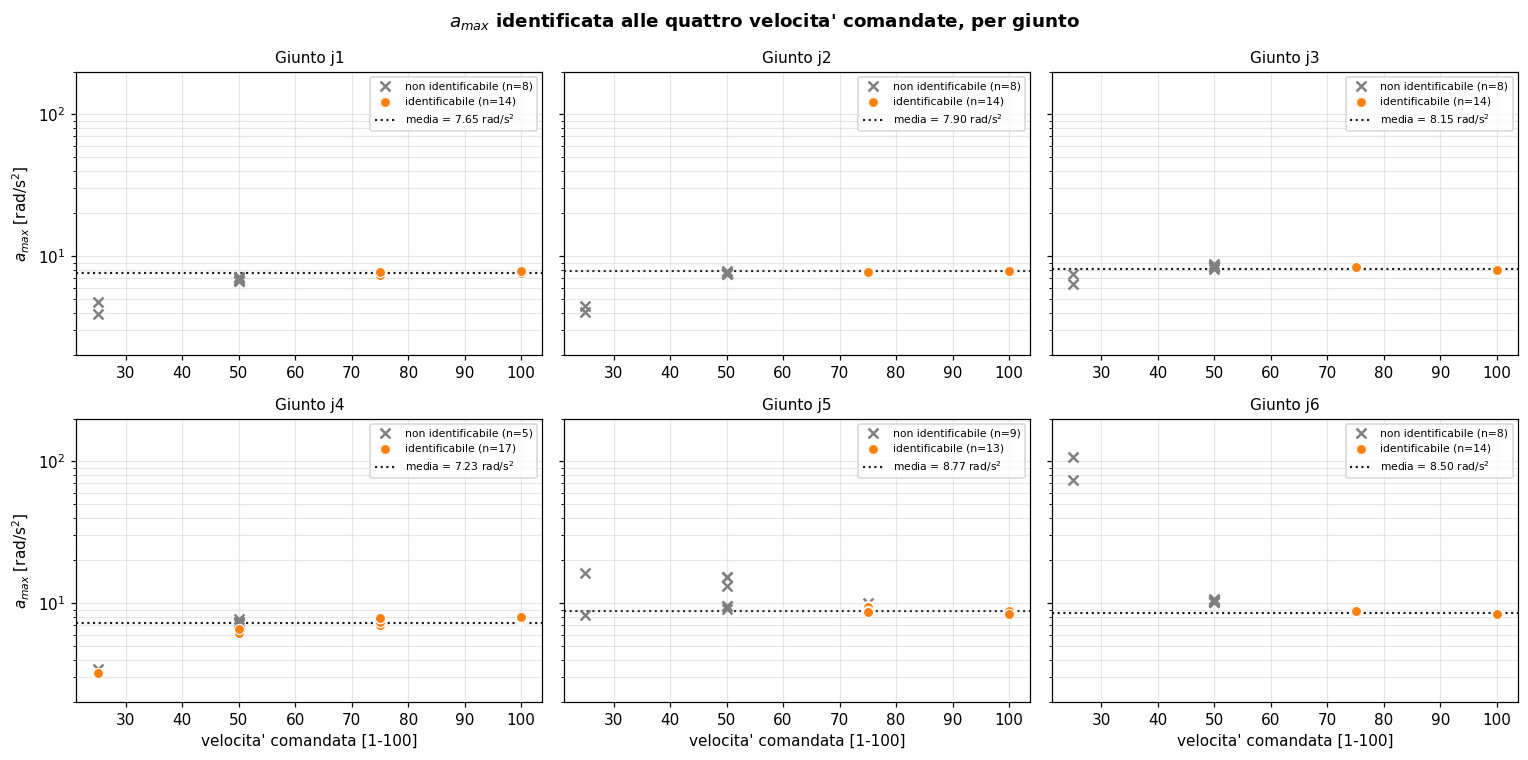

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)

for ax, giunto in zip(axes.flatten(), sorted(fit.joint_name.unique())):
    plot_amax_across_speeds(fit, giunto, ax=ax)
    ax.set_ylim(2, 200)

for ax in axes[0, :]:
    ax.set_xlabel("")
for ax in axes[:, 1:].flatten():
    ax.set_ylabel("")

fig.suptitle("$a_{max}$ identificata alle quattro velocita' comandate, per giunto",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "04_amax_per_giunto.png", dpi=150, bbox_inches="tight")
plt.show()

I punti arancioni — movimenti con rampa risolta — si allineano su una costante attorno a
**8 rad/s²**, la stessa a velocità 75 e 100. Le croci grigie si sparpagliano su oltre un
ordine di grandezza, fino a 90 rad/s² per `j6` a velocità 25, dove la rampa dura **0.19
campioni**.

> `amax` **non** dipende dalla velocità comandata. Il CV grezzo, fra l'8.7% e il 137.9%,
> misura l'**identificabilità del parametro**, non la fisica del giunto: sui movimenti in
> cui è misurabile scende sotto il 5% su cinque giunti su sei.

Applicando il criterio ai valori grezzi si sarebbe concluso il contrario, cosa priva di
senso fisico.

### Un giunto si comporta diversamente dagli altri

Due diagnostiche indipendenti puntano allo stesso posto.

In [18]:
per_giunto = validazione.pivot_table(index="joint_name", columns="commanded_velocity",
                                     values="rmse_quanti", aggfunc="median").round(2)
per_giunto["mediana"] = validazione.groupby("joint_name").rmse_quanti.median().round(2)
print("RMSE mediano in quanti di encoder, per giunto e velocita':")
print(per_giunto.to_string())

print("\nI movimenti fuori norma:")
print(validazione[validazione.fuori_norma][
    ["session", "joint_name", "commanded_velocity", "rmse_quanti"]
].to_string(index=False))

RMSE mediano in quanti di encoder, per giunto e velocita':
commanded_velocity    25    50    75   100  mediana
joint_name                                         
j1                  0.93  1.38  2.24  2.79     2.27
j2                  2.94  2.90  2.99  3.26     3.02
j3                  1.23  1.59  1.88  2.31     1.97
j4                  2.06  2.58  3.11  4.33     2.83
j5                  1.23  1.74  2.64  3.12     2.54
j6                  0.69  1.09  1.75  2.29     1.75

I movimenti fuori norma:
session joint_name  commanded_velocity  rmse_quanti
  1_100         j4                 100     4.952064
  2_100         j4                 100     5.001962
  3_100         j4                 100     5.176355
   3_75         j4                  75     4.130370
  4_100         j4                 100     4.731651


`j4` ha residui **sistematicamente più alti a tutte e quattro le velocità** (mediana
2.0–2.3 quanti contro 0.6–1.6 degli altri) e tutti i movimenti fuori norma sono suoi. Non è
spiegabile coi parametri: a velocità 100 ha `vmax` e `amax` in linea con gli altri e lo
stesso spostamento. La causa si vede guardando *dove* cade il residuo: **`j4` non si ferma
quando e dove il modello dice**.

Il CV di `amax` di `j4` (33.7%) ha invece una causa banale — identificabilità marginale:
alzando la soglia da 5 a 6 campioni scende a **4.1%**. Le due segnalazioni hanno origini
distinte, e solo la prima è un fenomeno fisico.

In [19]:
# Soglia di identificabilita' piu' severa: il CV di j4 rientra.
for soglia in (5, 6, 7):
    rep = check_amax_consistency_across_speeds(
        fit, "j4", ValidationConfig(min_ramp_samples=soglia)
    )
    sub = fit[(fit.joint_name == "j4") & (fit.ramp_samples >= soglia)]
    per_vel = sub.groupby("commanded_velocity").amax_fit.mean()
    cv = per_vel.std() / per_vel.mean() if len(per_vel) > 1 else np.nan
    print(f"soglia {soglia} campioni: {len(sub):2d} movimenti, "
          f"{len(per_vel)} velocita' utili, CV = {100*cv:5.1f}%, "
          f"amax = {per_vel.mean():.2f} rad/s^2")

soglia 5 campioni: 17 movimenti, 4 velocita' utili, CV =  33.7%, amax = 6.19 rad/s^2
soglia 6 campioni: 14 movimenti, 2 velocita' utili, CV =   4.1%, amax = 7.62 rad/s^2
soglia 7 campioni: 10 movimenti, 2 velocita' utili, CV =   8.2%, amax = 7.41 rad/s^2


### Residui a confronto: tipico contro anomalo

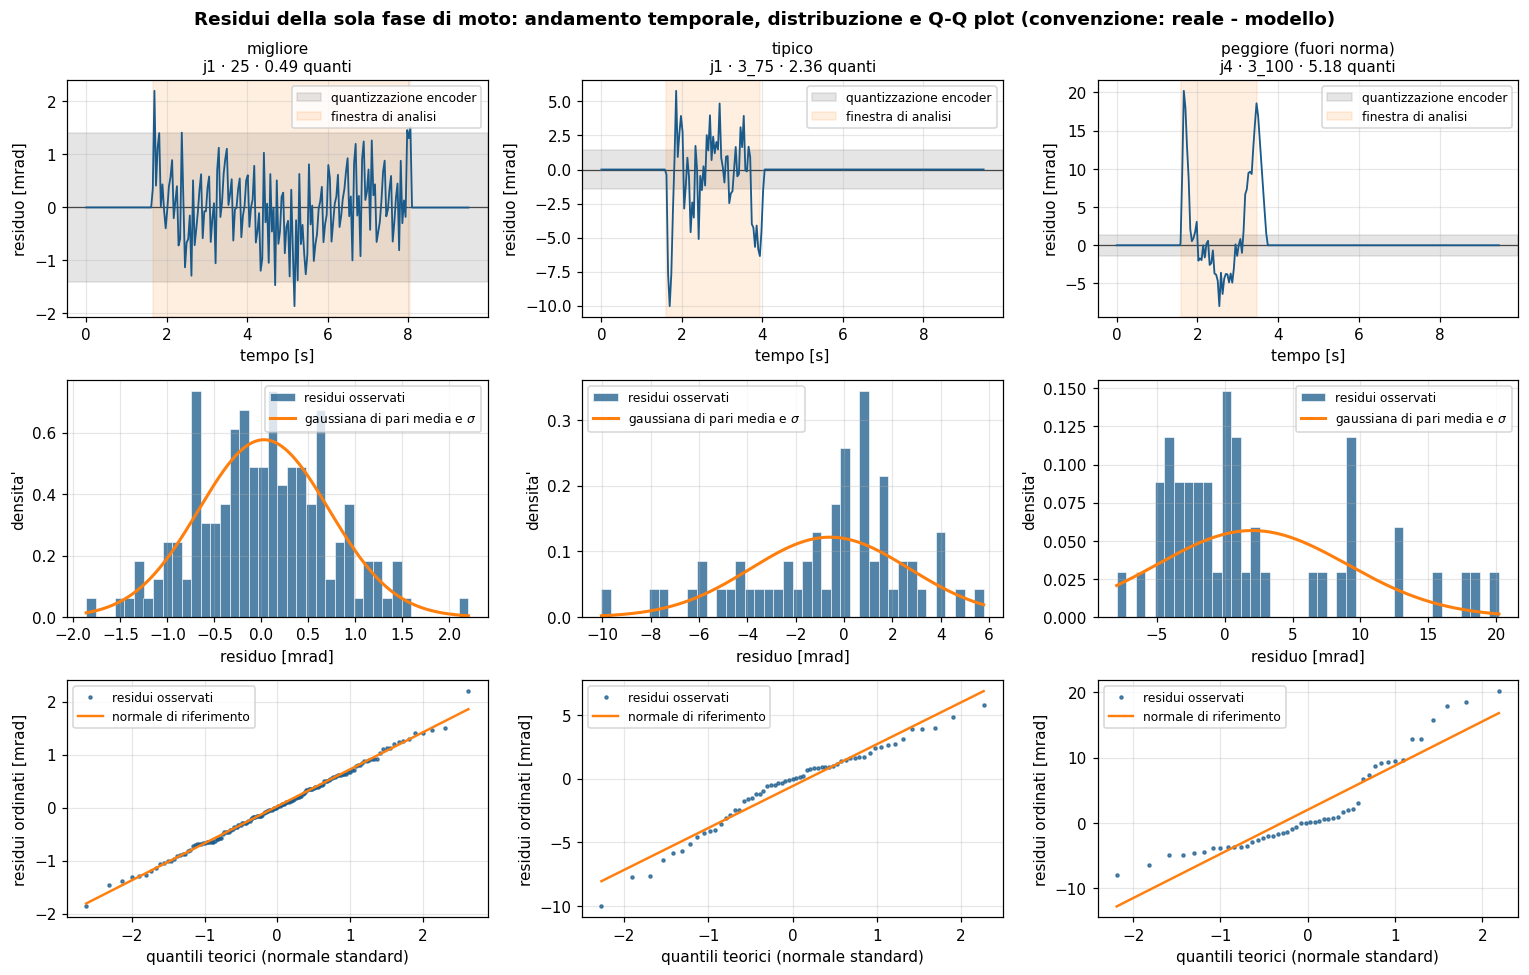

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    movimenti_val = load_movements_from_processed(
        DATA_PROCESSED / "preprocessing_params.csv", raw_root=DATA_RAW
    )
indice = {(m["session"], m["joint_name"], m["segment_index"]): m
          for m in movimenti_val.values()}

validi = validazione[validazione.validato]
scelti = [
    ("migliore", validi.loc[validi.rmse_quanti.idxmin()]),
    ("tipico", validi.iloc[(validi.rmse_quanti - validi.rmse_quanti.median()).abs().argmin()]),
    ("peggiore (fuori norma)", validi.loc[validi.rmse_quanti.idxmax()]),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for col, (etichetta, riga) in enumerate(scelti):
    mov = indice[(riga.session, riga.joint_name, int(riga.segment_index))]
    fr = fit[(fit.session == riga.session) & (fit.joint_name == riga.joint_name)
             & (fit.segment_index == riga.segment_index)].iloc[0]

    s = compute_residuals_summary(mov["t_data"], mov["q_data"], mov["q0"], mov["qf"],
                                  fr.to_dict(), riga.profile_type)
    titolo = (f"{etichetta}\n{riga.joint_name} · {riga.session} · "
              f"{riga.rmse_quanti:.2f} quanti")
    # L'andamento temporale mostra tutto il segmento, con evidenziata la finestra usata
    # per le metriche; distribuzione e Q-Q usano i soli campioni in moto.
    plot_residuals_vs_time(mov["t_data"], s.residuals, titolo, ax=axes[0, col],
                           mask=s.motion_mask)
    plot_residuals_histogram(s.residuals, "", ax=axes[1, col], mask=s.motion_mask)
    plot_residuals_qq(s.residuals, "", ax=axes[2, col], mask=s.motion_mask)

fig.suptitle("Residui della sola fase di moto: andamento temporale, distribuzione "
             "e Q-Q plot (convenzione: reale - modello)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "04_residui_confronto.png", dpi=150, bbox_inches="tight")
plt.show()

Le tre righe rispondono a domande diverse: **dove** il modello sbaglia nel tempo, **come**
si distribuiscono gli errori, e **in che modo** quella distribuzione si discosta dalla
normale. I tre casi formano un gradiente leggibile — 0.49 quanti nel migliore (`j1 · 25`),
2.36 nel tipico (`j1 · 3_75`), 5.18 nel peggiore (`j4 · 3_100`).

Nel **migliore** il residuo resta dentro la banda di quantizzazione; nel **tipico** compare
una struttura contenuta ai raccordi; nel **peggiore** si vedono due escursioni di ~20 mrad
in corrispondenza dei raccordi — non rumore, ma il modello che sbaglia sempre negli stessi
punti.

Il Q-Q plot rende visibile la stessa progressione in forma diversa. Nel caso **migliore** i
punti seguono la retta e l'unica irregolarità sono piccoli scalini, che sono i livelli
discreti dell'encoder. Nel **tipico** compaiono code leggere alle due estremità, prodotte
dai raccordi. Nel **peggiore** la curvatura a S è marcata: gli errori grandi sono molto più
frequenti di quanto una gaussiana preveda, ed è la firma di un errore sistematico.

> **La non-normalità è attesa, e non è un difetto del modello.** Su posizioni quantizzate a
> 1.4·10⁻³ rad e campionate a 25 Hz i residui non possono essere gaussiani. Il Q-Q plot
> serve a distinguere le due cause che si sovrappongono — la quantizzazione, che produce i
> gradini, e l'errore del modello ai raccordi, che produce le code — non a promuovere o
> bocciare il modello. Quel giudizio resta affidato a `rmse_quanti`, il residuo rapportato
> al suo pavimento fisico.

#### L'assestamento finale, misurato

Se `j4` continua a muoversi dopo la fine del profilo, deve vedersi confrontando la
posizione reale col bersaglio nei campioni successivi all'istante di arrivo previsto.

In [21]:
righe = []
for chiave, m in movimenti_val.items():
    fr = fit[(fit.session == m["session"]) & (fit.joint_name == m["joint_name"])
             & (fit.segment_index == m["segment_index"])]
    if not len(fr) or not fr.iloc[0].success:
        continue
    fr = fr.iloc[0]
    t_fine = fr.t0_fit + abs(fr.delta_q) / fr.vmax_fit + fr.vmax_fit / fr.amax_fit
    dopo = m["t_data"] > t_fine + 0.2          # margine oltre l'arrivo previsto
    if dopo.sum() < 5:
        continue
    righe.append({
        "joint_name": m["joint_name"],
        "commanded_velocity": fr.commanded_velocity,
        # quanto dista ancora dal bersaglio, in media, dopo l'arrivo previsto
        "scarto_finale_mrad": 1e3 * np.abs(m["q_data"][dopo] - m["qf"]).mean(),
    })

assestamento = pd.DataFrame(righe)
riepilogo_ass = assestamento.groupby("joint_name").scarto_finale_mrad.agg(
    mediano="median", massimo="max").round(3)
riepilogo_ass.to_csv(TABLES / "04_assestamento_finale.csv")
print("Scarto dal bersaglio dopo l'istante di arrivo previsto [mrad]:")
print(riepilogo_ass.to_string())
print(f"\nquantizzazione encoder = {1.4:.1f} mrad")

Scarto dal bersaglio dopo l'istante di arrivo previsto [mrad]:
            mediano  massimo
joint_name                  
j1            0.002    1.137
j2            0.005    1.195
j3            0.002    0.002
j4            0.044    4.117
j5            0.002    0.780
j6            0.002    0.002

quantizzazione encoder = 1.4 mrad


Cinque giunti su sei arrivano al bersaglio entro un quanto di encoder e ci restano, mentre
`j4` sbanda fino a **4.1 mrad** in media, e nel caso peggiore parte da 18 mrad e impiega
due secondi a rientrare.

Il modello cinematico non può catturarlo perché non descrive la dinamica dell'anello di
controllo: un sottotiro seguito da avvicinamento lento è la firma di gioco meccanico,
elasticità della trasmissione o di un termine integrale lento. Spiega interamente perché
`j4` abbia residui doppi rispetto agli altri.

## 8. Il simulatore

I parametri identificati tornano dentro un modello che **riproduce il robot**. Ogni giunto
esegue un trapezoidale asimmetrico a tempo minimo con tre numeri:

| parametro | valore | da dove viene |
|---|---|---|
| `vmax_per_unit` | 0.026388 rad/s per unità di comando | regressione di `vmax` sul comando |
| `a_acc` | 8.70 rad/s² | mediana del fit asimmetrico, rampa risolta |
| `a_dec` | 7.52 rad/s² | idem |

L'interfaccia è la stessa del robot vero — `send_q_ref(q_ref, vel)` — quindi il simulatore
è sostituibile all'hardware.

In [22]:
from src.simulator import MyCobot280Simulator, SimulatorParams, validate_simulator

par = SimulatorParams()
print(f"vmax a comando 100 : {par.vmax(100):.4f} rad/s")
print(f"a_acc / a_dec      : {par.a_acc:.2f} / {par.a_dec:.2f} = {par.a_acc/par.a_dec:.3f}")
print()

# Un comando come quello dell'acquisizione: giunto 1 da 0 a +120 gradi.
sim = MyCobot280Simulator()
t_sim, Q_sim = sim.send_q_ref(np.deg2rad([120, 0, 0, 0, 0, 0]), vel=100)
print(f"comando singolo    : {len(t_sim)} campioni, {t_sim[-1]:.2f} s")
print(f"posizione di arrivo: {np.rad2deg(Q_sim[-1, 0]):.1f} gradi")

vmax a comando 100 : 2.6388 rad/s
a_acc / a_dec      : 8.70 / 7.52 = 1.157

comando singolo    : 30 campioni, 1.16 s
posizione di arrivo: 120.0 gradi


### Quanto è accurato

Ogni movimento viene riprodotto con i parametri **nominali**, senza rifittare nulla: si
misura l'errore di chi usasse il simulatore senza altra informazione.

L'unica grandezza allineata è `t0`, che non è un parametro del modello ma l'istante in cui
il comando seriale è arrivato. Senza allinearlo si misurerebbe la latenza della
trasmissione: a comando 100 un campione di disallineamento vale 0.105 rad, cioè **75 quanti
di encoder**.

In [23]:
accuratezza = validate_simulator(DATA_RAW)
accuratezza.to_csv(DATA_PROCESSED / "simulator_accuracy.csv", index=False)

print(f"errore mediano : {accuratezza.rmse_quanti.median():.2f} quanti di encoder "
      f"= {np.rad2deg(accuratezza.rmse.median()):.3f} gradi")
print(f"90esimo perc.  : {accuratezza.rmse_quanti.quantile(0.9):.2f} quanti")
print(f"massimo        : {accuratezza.rmse_quanti.max():.2f} quanti")
print()
print(accuratezza.groupby("commanded_velocity").rmse_quanti
      .agg(["median", "max", "count"]).round(2))

errore mediano : 3.97 quanti di encoder = 0.319 gradi
90esimo perc.  : 7.71 quanti
massimo        : 13.52 quanti

                    median    max  count
commanded_velocity                      
25.0                  2.48   8.77     12
50.0                  3.99   9.79     36
75.0                  4.06  13.52     36
100.0                 4.19   9.39     48


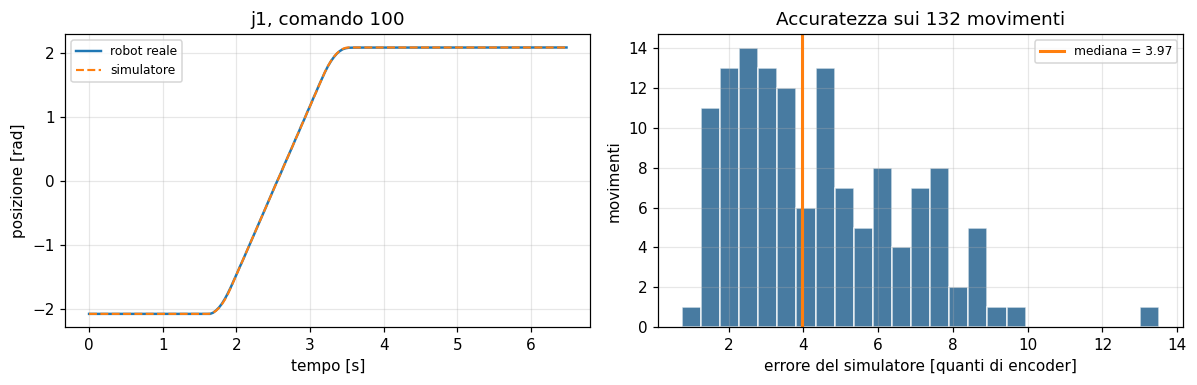

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

# Un movimento reale contro la sua simulazione.
mov = list(movimenti.values())[0]
from src.trajectory_models import asymmetric_position, asymmetric_times
from src.simulator import _onset
from scipy.optimize import minimize_scalar

q0, qf = mov["q0"], mov["qf"]
vmax_nom = par.vmax(mov["commanded_velocity"])
dur = asymmetric_times(q0, qf, vmax_nom, par.a_acc, par.a_dec).t_total
f = lambda t0: np.sqrt(np.mean((mov["q_data"] - asymmetric_position(
    mov["t_data"], q0, qf, vmax_nom, par.a_acc, par.a_dec, t0=t0))**2))
t0_all = minimize_scalar(f, bounds=(_onset(mov["t_data"], mov["q_data"]) - 0.5,
                                    _onset(mov["t_data"], mov["q_data"]) + 0.5),
                         method="bounded").x
q_sim = asymmetric_position(mov["t_data"], q0, qf, vmax_nom, par.a_acc, par.a_dec, t0=t0_all)

ax1.plot(mov["t_data"], mov["q_data"], lw=1.6, label="robot reale")
ax1.plot(mov["t_data"], q_sim, lw=1.4, ls="--", label="simulatore")
ax1.set(xlabel="tempo [s]", ylabel="posizione [rad]",
        title=f"{mov['joint_name']}, comando {mov['commanded_velocity']:.0f}")
ax1.legend(fontsize=8)

ax2.hist(accuratezza.rmse_quanti, bins=25, color="#1a5a8a", alpha=0.8, edgecolor="white")
ax2.axvline(accuratezza.rmse_quanti.median(), color="#ff7f0e", lw=2,
            label=f"mediana = {accuratezza.rmse_quanti.median():.2f}")
ax2.set(xlabel="errore del simulatore [quanti di encoder]", ylabel="movimenti",
        title="Accuratezza sui 132 movimenti")
ax2.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "05_accuratezza_simulatore.png", dpi=150, bbox_inches="tight")

**Il simulatore riproduce il robot entro 3.97 quanti di encoder, cioè 0.32 gradi.**

Con parametri liberi per ogni movimento il residuo è 1.72 quanti; con tre parametri uguali
per tutti sale a 3.97. La differenza è il **prezzo della generalizzazione**, ed è ciò che
si vuole misurare: un simulatore serve proprio quando i parametri non si conoscono.

Sostituire i tre numeri globali con parametri **per giunto** peggiora l'accordo (4.19
contro 3.97 quanti): fra i sei giunti `a_acc` e `a_dec` variano del 5% e `vmax_per_unit`
dello 0.6%, dispersione che è rumore di stima e non struttura fisica. **Tre numeri
descrivono l'intero robot.**

## 9. Limiti e sviluppi futuri

* **Il campionamento a 25 Hz è il limite dominante.** Sotto ~5 campioni di rampa il residuo
  diventa insensibile ad `amax`, su 46 movimenti su 132. Riacquisire a 100 Hz lo renderebbe
  identificabile ovunque: è la raccomandazione operativa più concreta del lavoro.
* **L'asimmetria fra le rampe resta da spiegare.** Il confronto stabilisce *che* c'è, non
  *perché*; il notebook `02` esclude l'effetto direzionale, il che rende la spiegazione
  gravitazionale poco probabile.
* **Nessun profilo triangolare nel dataset:** tutti i movimenti hanno escursione ~4.2 rad.
  Quel ramo del modello è validato solo su segnali sintetici.
* **`q0` e `qf` sono fissi nel fit**: un errore di posizionamento a regime finisce nel
  residuo invece che in un parametro.